# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Suhail Ainur Rofiq | 5054251046 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [15]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

In [16]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [17]:
df.shape

(200, 5)

In [18]:
df.dtypes

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

In [19]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [20]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

Series([], dtype: int64)


Tidak ada missing value

In [21]:
duplikat = df.duplicated().sum()
print(duplikat)

0


Tidak ada baris duplikat

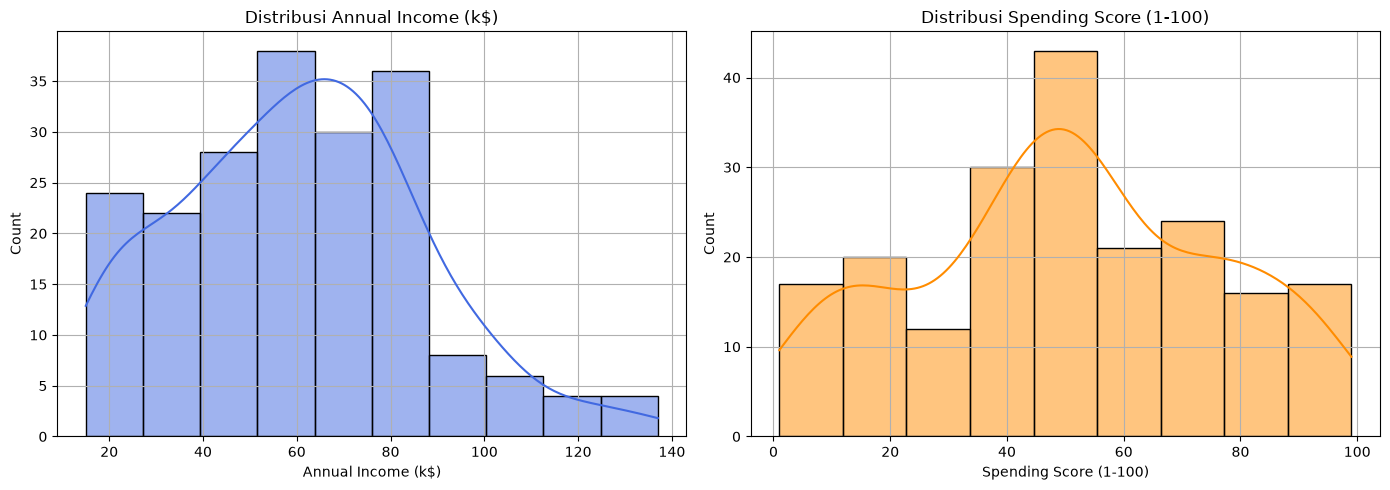

In [22]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot pertama diarahkan ke axes[0] (kotak sebelah kiri)
sns.histplot(
    data=df, 
    x='Annual Income (k$)', 
    kde=True, ax=axes[0], 
    color='royalblue'
    )
axes[0].set_title('Distribusi Annual Income (k$)', fontsize=12)
axes[0].grid(True)

# Plot kedua diarahkan ke axes[1] (kotak sebelah kanan)
sns.histplot(
    data=df, 
    x='Spending Score (1-100)', 
    kde=True, 
    ax=axes[1], 
    color='darkorange'
    )
axes[1].set_title('Distribusi Spending Score (1-100)', fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()


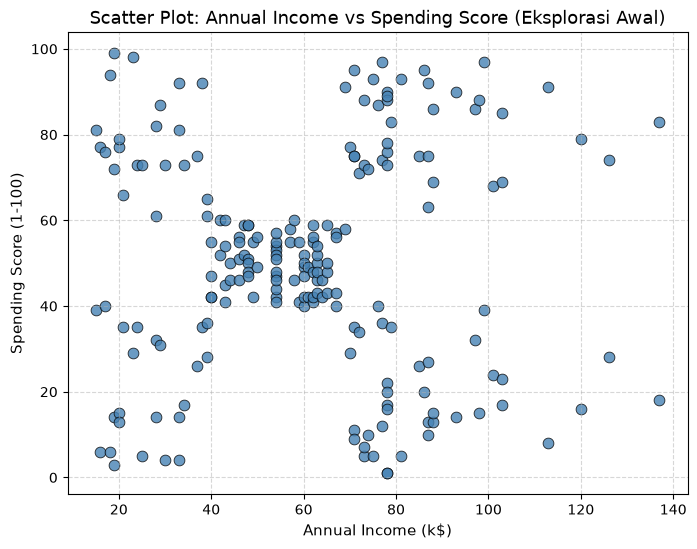

In [23]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    color='steelblue',
    s=60,
    edgecolor='black',
    alpha=0.8
)
plt.title('Scatter Plot: Annual Income vs Spending Score (Eksplorasi Awal)', fontsize=13)
plt.xlabel('Annual Income (k$)', fontsize=11)
plt.ylabel('Spending Score (1-100)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

1. Tidak ada missing value (semua 200 baris terisi penuh) dan tidak ada baris yang terduplikasi
2. Annual Income (k$): Rentang antara $15k hingga $137k, dengan rata-rata $60.56k dan median $61.5k. Distribusinya relatif normal dengan sedikit kemencengan ke kanan (slight right-skewness) pada pendapatan di atas $100k. Spending Score (1-100): Rentang antara skor 1 hingga 99, dengan rata-rata 50.20 dan median 50.00. Distribusi simetris terpusat di area tengah.
3. Pendapatan rendah – Pengeluaran rendah (kiri bawah). Pendapatan rendah – Pengeluaran tinggi (kiri atas). Pendapatan menengah – Pengeluaran menengah (pusat data). Pendapatan tinggi – Pengeluaran rendah (kanan bawah). Pendapatan tinggi – Pengeluaran tinggi (kanan atas)

# 2. Preprocessing

In [24]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
print("Dimensi data X:", X.shape)
X.head()

Dimensi data X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
# Feature scaling menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Tampilkan beberapa baris dan ringkasan statistik
print("Statistik Deskriptif X_scaled:")
X_scaled.head()

Statistik Deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [43]:
X_scaled.describe().round(4)

,Annual Income (k$),Spending Score (1-100)
count,200.0000,200.0000
mean,-0.0000,-0.0000
std,1.0025,1.0025
min,-1.7390,-1.9100
25%,-0.7275,-0.5998
50%,0.0359,-0.0078
75%,0.6657,0.8851
max,2.9177,1.8945


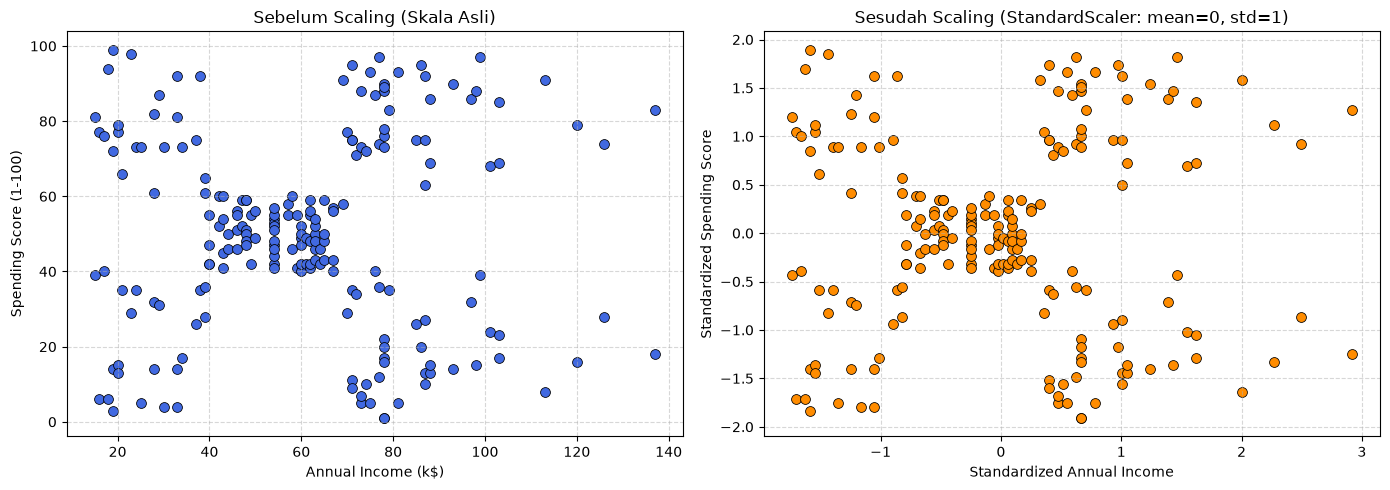

In [44]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
# Scatter plot perbandingan sebelum dan sesudah scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sebelum scaling
sns.scatterplot(
    data=X, x='Annual Income (k$)', y='Spending Score (1-100)',
    ax=axes[0], color='royalblue', s=50, edgecolor='k'
)
axes[0].set_title('Sebelum Scaling (Skala Asli)', fontsize=12)
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Sesudah scaling
sns.scatterplot(
    data=X_scaled, x='Annual Income (k$)', y='Spending Score (1-100)',
    ax=axes[1], color='darkorange', s=50, edgecolor='k'
)
axes[1].set_title('Sesudah Scaling (StandardScaler: mean=0, std=1)', fontsize=12)
axes[1].set_xlabel('Standardized Annual Income')
axes[1].set_ylabel('Standardized Spending Score')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Mengapa Annual Income dan Spending Score dipilih?
Kedua fitur ini secara langsung merefleksikan kapasitas finansial (income) dan kecenderungan konsumtif (spending habit) dari pelanggan. Kombinasi keduanya menghasilkan segmentasi bisnis yang sangat terarah, seperti mengidentifikasi pelanggan loyal berdaya beli tinggi vs pelanggan hemat.

Mengapa CustomerID tidak digunakan?
CustomerID hanyalah angka indeks artifisial. Mengikutsertakan variabel ini akan menimbulkan bias spurious correlation karena jarak Euclidean antar ID tidak memiliki representasi perilaku ekonomi pelanggan.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [45]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
# Jalankan DBSCAN pada X_scaled dengan parameter awal
dbscan_model = DBSCAN(eps=0.35, min_samples=5)
labels_dbscan = dbscan_model.fit_predict(X_scaled)

Pada data terstandarisasi, nilai jarak Euclidean antar titik berada dalam satuan standar deviasi. Nilai eps=0.35 dan min_samples=5 merupakan titik awal yang baik untuk menangkap cluster padat tanpa membuat semua titik dianggap noise.

In [46]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
# Hitung distribusi label
label_counts = pd.Series(labels_dbscan).value_counts().sort_index()
print("Distribusi jumlah data per label:")
print(label_counts)

# Hitung jumlah cluster (tanpa -1) dan noise
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = np.sum(labels_dbscan == -1)

print(f"\nJumlah cluster yang terbentuk (tanpa noise): {n_clusters_dbscan}")
print(f"Jumlah titik noise (label -1): {n_noise_dbscan}")

Distribusi jumlah data per label:
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64

Jumlah cluster yang terbentuk (tanpa noise): 6
Jumlah titik noise (label -1): 23


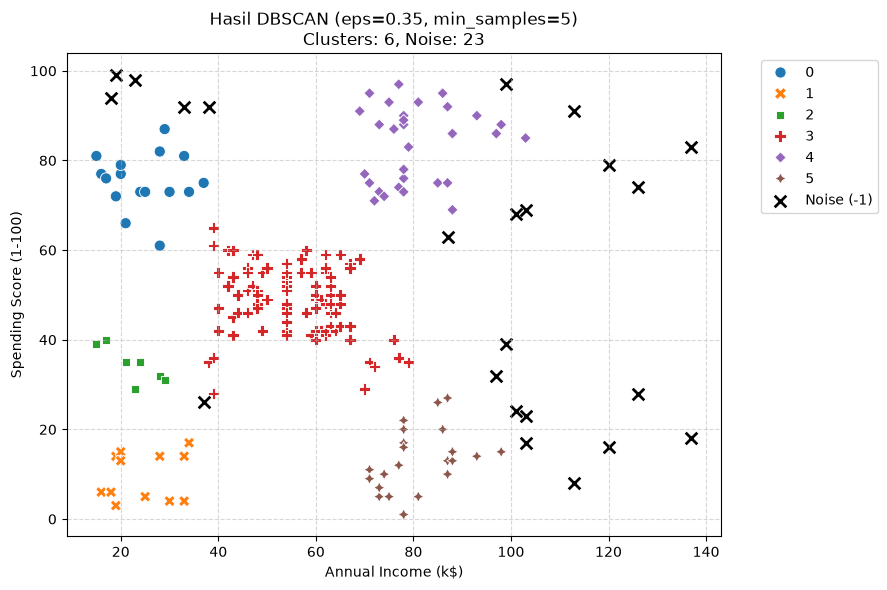

In [47]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
# Scatter plot hasil DBSCAN pada fitur asli X
plt.figure(figsize=(9, 6))
palette = sns.color_palette('tab10', n_clusters_dbscan)

# Plot titik non-noise
sns.scatterplot(
    x=X['Annual Income (k$)'][labels_dbscan != -1],
    y=X['Spending Score (1-100)'][labels_dbscan != -1],
    hue=labels_dbscan[labels_dbscan != -1],
    palette=palette,
    s=65,
    style=labels_dbscan[labels_dbscan != -1],
    legend='full'
)

# Plot titik noise secara terpisah dengan simbol silang (X) hitam
if n_noise_dbscan > 0:
    plt.scatter(
        X['Annual Income (k$)'][labels_dbscan == -1],
        X['Spending Score (1-100)'][labels_dbscan == -1],
        color='black',
        marker='x',
        s=70,
        linewidths=2,
        label='Noise (-1)'
    )

plt.title(f'Hasil DBSCAN (eps=0.35, min_samples=5)\nClusters: {n_clusters_dbscan}, Noise: {n_noise_dbscan}', fontsize=12)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [48]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
# Tuning parameter eps dan min_samples
eps_values = [0.25, 0.30, 0.35, 0.40, 0.45]
min_samples_values = [3, 4, 5, 6, 7]

summary_dbscan = []

for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms)
        lbls = db.fit_predict(X_scaled)
        
        n_clusters = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_noise = np.sum(lbls == -1)
        
        # Validasi perhitungan Silhouette: minimal 2 cluster dan data non-noise cukup
        if n_clusters >= 2 and (len(X_scaled) - n_noise) > n_clusters:
            mask = lbls != -1
            sil = silhouette_score(X_scaled[mask], lbls[mask])
        else:
            sil = np.nan
            
        summary_dbscan.append({
            'eps': eps,
            'min_samples': ms,
            'Jumlah Cluster': n_clusters,
            'Jumlah Noise': n_noise,
            'Silhouette Score (Non-Noise)': round(sil, 4) if not np.isnan(sil) else None
        })

df_dbscan_summary = pd.DataFrame(summary_dbscan)
df_dbscan_summary.dropna().sort_values(by='Silhouette Score (Non-Noise)', ascending=False).head(10)

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Silhouette Score (Non-Noise)
9,0.30,7,4,72,0.6452
4,0.25,7,5,77,0.5945
14,0.35,7,5,47,0.5708
3,0.25,6,6,69,0.5623
12,0.35,5,6,23,0.5577
1,0.25,4,7,43,0.5380
2,0.25,5,6,50,0.5317
8,0.30,6,6,48,0.5302
7,0.30,5,7,35,0.5243
6,0.30,4,8,23,0.5197


Pengaruh kenaikan eps:
Meningkatkan eps memperbesar radius pencarian ketetanggaan. Akibatnya, titik-titik yang agak berjauhan menjadi lebih mudah terhubung. Titik noise berkurang drastis, tetapi jika eps terlalu besar (misal $\ge 0.45$), cluster-cluster yang berdekatan akan melebur (merge) menjadi satu cluster raksasa.

Pengaruh min_samples:
Meningkatkan min_samples memperketat syarat suatu titik menjadi core point. Akibatnya, cluster yang terbentuk lebih murni dan padat, namun jumlah titik yang diklasifikasikan sebagai noise bertambah banyak.

Kombinasi parameter ekstrem:Bila eps=0.20, jarak terlalu sempit sehingga lebih dari 70 titik terbuang sebagai noise.Bila eps=0.45 dengan min_samples=4, cluster tengah dan sekitarnya menyatu menjadi 3-4 cluster besar dengan noise yang sangat sedikit.Karakteristik kepadatan dataset ini bervariasi: area tengah jauh lebih padat dibanding area sudut, sehingga DBSCAN dengan satu parameter global $(\varepsilon)$ kesulitan menghasilkan 5 cluster sempurna tanpa mengorbankan sebagian data sebagai noise.

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [49]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
# Latih model Birch pada X_scaled dengan parameter awal
birch_model = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch_model.fit_predict(X_scaled)

In [50]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
# Tampilkan anggota setiap cluster
birch_counts = pd.Series(labels_birch).value_counts().sort_index()
print("Distribusi anggota cluster BIRCH:")
print(birch_counts)
print(f"\nJumlah cluster yang terbentuk: {len(birch_counts)}")

Distribusi anggota cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster yang terbentuk: 5


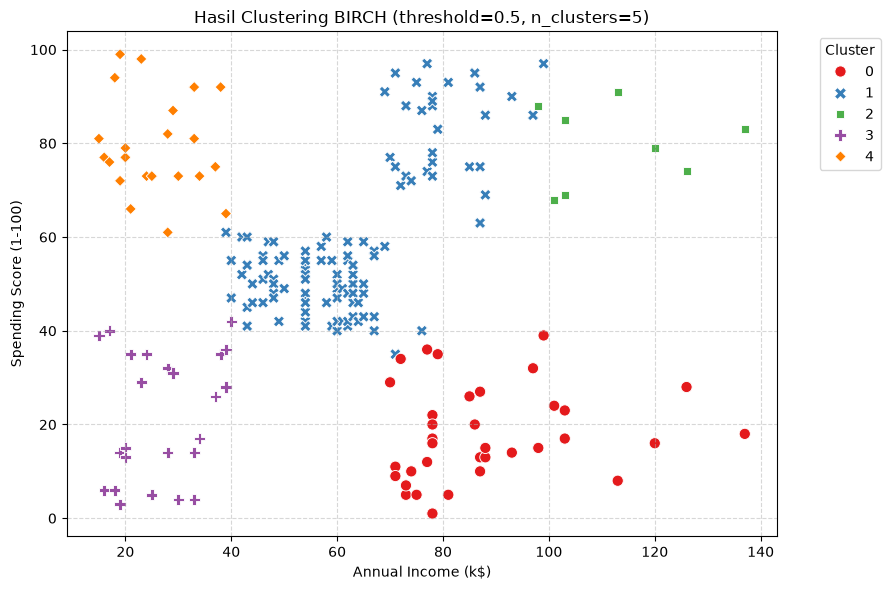

In [51]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
# Scatter plot hasil BIRCH pada fitur asli X
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_birch,
    palette='Set1',
    s=65,
    style=labels_birch,
    legend='full'
)
plt.title(f'Hasil Clustering BIRCH (threshold=0.5, n_clusters=5)', fontsize=12)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [53]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
# Bandingkan beberapa nilai threshold dengan n_clusters=5
threshold_candidates = [0.3, 0.5, 0.7, 1.0]
summary_birch = []

for th in threshold_candidates:
    brc = Birch(threshold=th, n_clusters=5)
    lbls = brc.fit_predict(X_scaled)
    n_c = len(set(lbls))
    sil = silhouette_score(X_scaled, lbls) if n_c > 1 else np.nan
    
    summary_birch.append({
        'Threshold': th,
        'n_clusters target': 5,
        'Jumlah Cluster Terbentuk': n_c,
        'Silhouette Score': round(sil, 4)
    })

df_birch_summary = pd.DataFrame(summary_birch)
df_birch_summary

c:\Users\LAPTOPKU\KULIAH\KULIAH SMT 3\ML-Praktik\ML-RKA-25-El\.venv\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,Threshold,n_clusters target,Jumlah Cluster Terbentuk,Silhouette Score
0,0.3,5,5,0.4781
1,0.5,5,5,0.4145
2,0.7,5,5,0.4207
3,1.0,5,4,0.3886


Pengaruh perbesaran threshold:
threshold merepresentasikan batas radius sub-cluster dalam node daun pohon CF. Jika diperbesar (misal 1.0), sub-cluster awal menyerap titik dalam jangkauan yang sangat lebar sehingga node daun yang terbentuk menjadi sangat sedikit. Jika jumlah sub-cluster lebih sedikit daripada n_clusters yang diminta, BIRCH tidak dapat membentuk jumlah cluster target.

Perbedaan BIRCH dan DBSCAN dalam menangani titik terpencil (outlier):
DBSCAN memisahkan titik terpencil sebagai noise (-1). Sebaliknya, BIRCH tidak memiliki mekanisme explicit noise rejection default; titik terpencil tetap dipaksa masuk ke dalam sub-cluster terdekat pada CF Tree, yang berpotensi menarik centroid cluster ke arah luar.

Pengaruh penetapan n_clusters:
Jika n_clusters=None, BIRCH hanya melakukan fase 1 (membangun CF Tree) dan mengembalikan label sub-cluster awal. Saat n_clusters ditentukan (misal 5), BIRCH mengeksekusi algoritma aglomeratif hirarkis pada level makro untuk menggabungkan sub-cluster menjadi sejumlah $k$ cluster akhir.

### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [54]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
# Latih GaussianMixture pada X_scaled menggunakan EM
gmm_model = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm_model.fit_predict(X_scaled)

In [56]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
# Tampilkan jumlah anggota per cluster
gmm_counts = pd.Series(labels_gmm).value_counts().sort_index()
print("Distribusi anggota cluster GMM:")
print(gmm_counts)

# Hitung matriks probabilitas keanggotaan
probabilities = gmm_model.predict_proba(X_scaled)
df_proba = pd.DataFrame(probabilities, columns=[f'Cluster_{i}' for i in range(5)])
df_proba['Max_Probability'] = df_proba.max(axis=1)
df_proba['Assigned_Cluster'] = labels_gmm

# Tampilkan 5 data dengan ketidakpastian tertinggi (probabilitas maksimal terendah)
print("\n5 Titik data dengan batas keanggotaan paling tidak pasti (borderline points):")
uncertain_points = df_proba.sort_values(by='Max_Probability').head(5)
uncertain_points

Distribusi anggota cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

5 Titik data dengan batas keanggotaan paling tidak pasti (borderline points):


,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Max_Probability,Assigned_Cluster
124,0.497063,4.020399e-07,5.610367e-14,5.029323e-01,4.143026e-06,0.502932,3
48,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381,0
49,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381,0
27,0.278521,4.886785e-04,6.746109e-01,1.610322e-12,4.637931e-02,0.674611,2
160,0.772053,1.625129e-05,1.301359e-16,2.279312e-01,6.913927e-09,0.772053,0


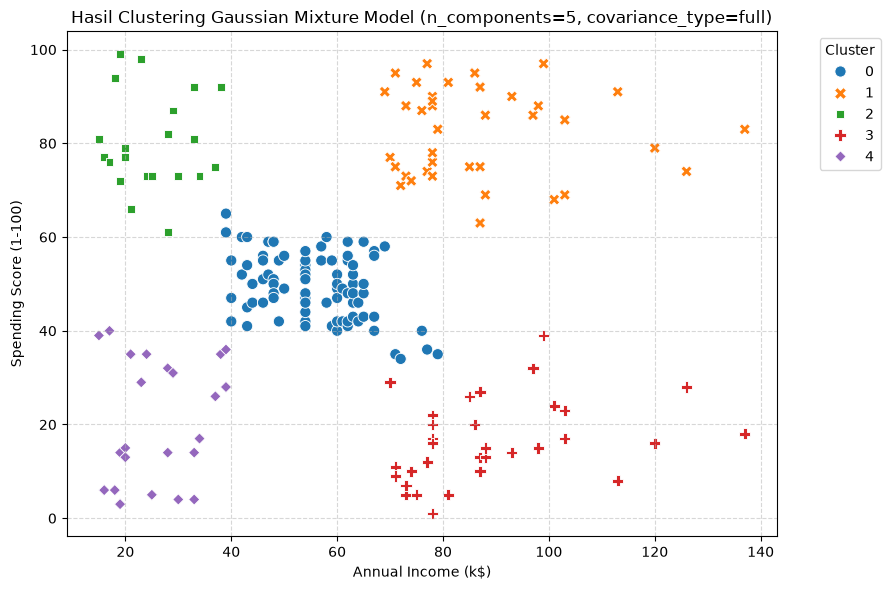

In [57]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
# Scatter plot hasil GMM pada fitur asli X
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_gmm,
    palette='tab10',
    s=65,
    style=labels_gmm,
    legend='full'
)
plt.title('Hasil Clustering Gaussian Mixture Model (n_components=5, covariance_type=full)', fontsize=12)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

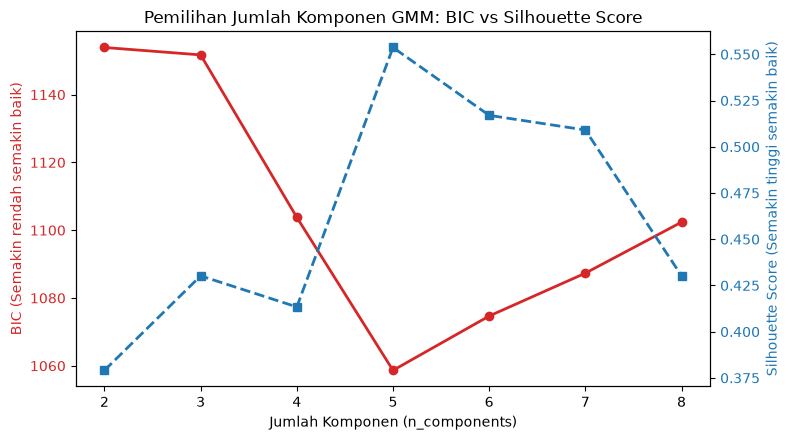

In [59]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
# Evaluasi komponen dari 2 hingga 8
n_range = range(2, 9)
bic_scores = []
silhouette_scores_gmm = []

for n in n_range:
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    lbls = gmm.fit_predict(X_scaled)
    bic_scores.append(gmm.bic(X_scaled))
    silhouette_scores_gmm.append(silhouette_score(X_scaled, lbls))

df_gmm_comparison = pd.DataFrame({
    'n_components': list(n_range),
    'BIC': [round(b, 2) for b in bic_scores],
    'Silhouette Score': [round(s, 4) for s in silhouette_scores_gmm]
})
df_gmm_comparison

# Plot kurva BIC dan Silhouette
fig, ax1 = plt.subplots(figsize=(8, 4.5))

color = 'tab:red'
ax1.set_xlabel('Jumlah Komponen (n_components)')
ax1.set_ylabel('BIC (Semakin rendah semakin baik)', color=color)
ax1.plot(n_range, bic_scores, marker='o', color=color, linewidth=2, label='BIC')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Silhouette Score (Semakin tinggi semakin baik)', color=color)
ax2.plot(n_range, silhouette_scores_gmm, marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Pemilihan Jumlah Komponen GMM: BIC vs Silhouette Score', fontsize=12)
fig.tight_layout()
plt.show()

$k=5$ menghasilkan BIC terendah (1058.65) sekaligus Silhouette Score tertinggi (0.5537). Ini mengonfirmasi secara matematis dan teoritis bahwa 5 cluster adalah partisi optimal untuk data ini.

Arti probabilitas keanggotaan:
Probabilitas $\gamma_{ik}$ mencerminkan derajat keyakinan posterior model bahwa pelanggan ke-$i$ berasal dari distribusi Gaussian ke-$k$. Pendekatan soft clustering ini mengakomodasi data yang berada di wilayah abu-abu (boundary points).

Pengaruh perubahan n_components:
Menambah komponen meningkatkan kompleksitas model. Bila terlalu sedikit ($k < 5$), klaster-klaster alami akan dipaksa menyatu (underfitting). Bila terlalu banyak ($k > 5$), satu kelompok alami akan terpecah secara artifisial, yang tercermin dari kenaikan nilai BIC akibat penalti kompleksitas parameter.

Mengapa jumlah cluster GMM harus ditentukan sebelum pelatihan?
GMM adalah model parametrik terarah. EM memerlukan inisialisasi awal sejumlah $K$ vektor rata-rata ($\mu$), matriks kovarians ($\Sigma$), dan bobot campuran ($\pi$) untuk menghitung fungsi log-likelihood. Tanpa $K$, ruang parameter tidak dapat ditentukan.

Apakah model dengan Silhouette tertinggi juga memiliki BIC terendah?
Ya, pada dataset ini terjadi keselarasan sempurna pada $k=5$, di mana nilai BIC berada pada titik minimum global (1058.65) dan Silhouette Score mencapai titik tertinggi (0.5537).

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [61]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
# Fungsi evaluasi internal untuk clustering
def evaluate_clustering_model(X_data, labels, model_name):
    unique_labels = set(labels)
    n_noise = np.sum(labels == -1)
    has_noise = -1 in unique_labels
    
    # Pisahkan noise dari evaluasi DBSCAN
    if has_noise:
        mask = labels != -1
        eval_X = X_data[mask]
        eval_labels = labels[mask]
        n_clusters = len(set(eval_labels))
    else:
        eval_X = X_data
        eval_labels = labels
        n_clusters = len(unique_labels)
        
    # Pastikan metrik valid untuk dihitung
    if n_clusters >= 2 and len(eval_X) > n_clusters:
        sil = silhouette_score(eval_X, eval_labels)
        db = davies_bouldin_score(eval_X, eval_labels)
        ch = calinski_harabasz_score(eval_X, eval_labels)
    else:
        sil, db, ch = np.nan, np.nan, np.nan
        
    return {
        'Model': model_name,
        'Jumlah Cluster': n_clusters,
        'Jumlah Noise': n_noise if has_noise else 0,
        'Silhouette Score': round(sil, 4),
        'Davies-Bouldin Index': round(db, 4),
        'Calinski-Harabasz Score': round(ch, 2)
    }

In [63]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
# Evaluasi ketiga model terbaik
eval_dbscan = evaluate_clustering_model(X_scaled, labels_dbscan, 'DBSCAN (eps=0.35, min_samples=5)')
eval_birch = evaluate_clustering_model(X_scaled, labels_birch, 'BIRCH (threshold=0.5, n_clusters=5)')
eval_gmm = evaluate_clustering_model(X_scaled, labels_gmm, 'GMM (n_components=5, full)')

df_comparison = pd.DataFrame([eval_dbscan, eval_birch, eval_gmm])
df_comparison

,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,"DBSCAN (eps=0.35, min_samples=5)",6,23,0.5577,0.5106,245.36
1,"BIRCH (threshold=0.5, n_clusters=5)",5,0,0.4145,0.6979,125.95
2,"GMM (n_components=5, full)",5,0,0.5537,0.5760,244.94


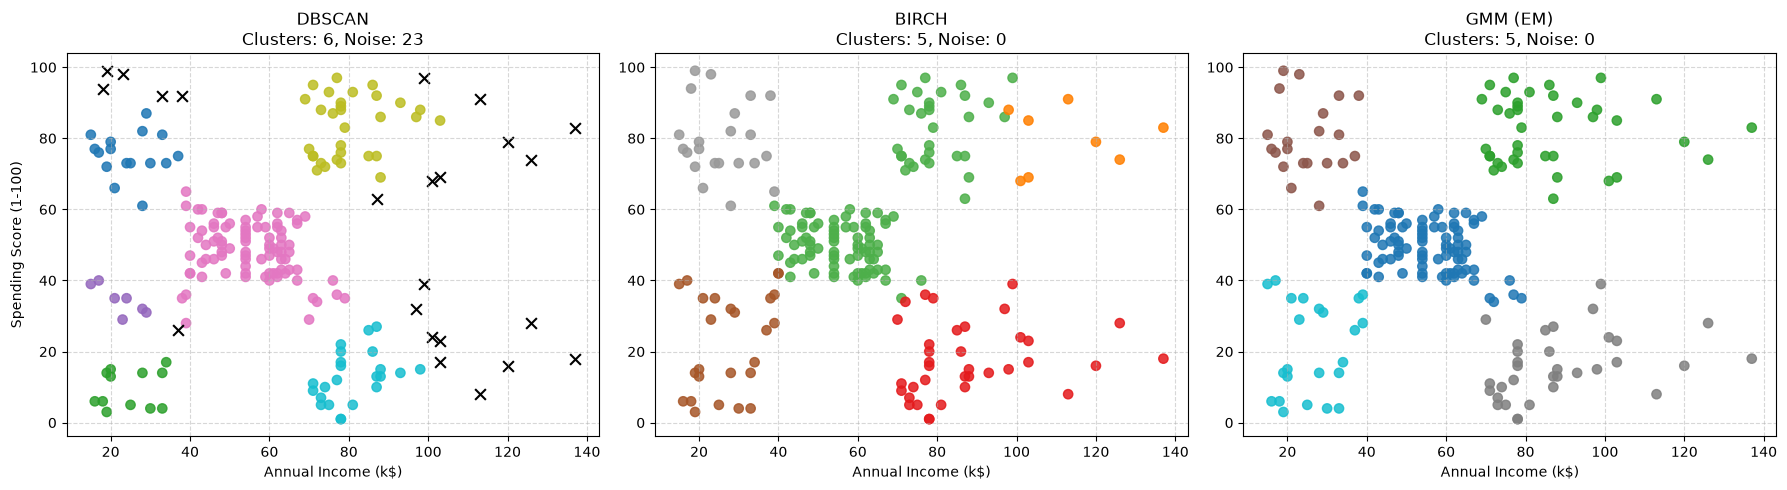

In [64]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
# Visualisasi perbandingan ketiga algoritma
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. DBSCAN Plot
axes[0].scatter(
    X['Annual Income (k$)'][labels_dbscan != -1],
    X['Spending Score (1-100)'][labels_dbscan != -1],
    c=labels_dbscan[labels_dbscan != -1],
    cmap='tab10', s=45, alpha=0.85
)
if n_noise_dbscan > 0:
    axes[0].scatter(
        X['Annual Income (k$)'][labels_dbscan == -1],
        X['Spending Score (1-100)'][labels_dbscan == -1],
        c='black', marker='x', s=60, label='Noise'
    )
axes[0].set_title(f'DBSCAN\nClusters: {n_clusters_dbscan}, Noise: {n_noise_dbscan}')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. BIRCH Plot
axes[1].scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=labels_birch,
    cmap='Set1', s=45, alpha=0.85
)
axes[1].set_title('BIRCH\nClusters: 5, Noise: 0')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. GMM Plot
axes[2].scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=labels_gmm,
    cmap='tab10', s=45, alpha=0.85
)
axes[2].set_title('GMM (EM)\nClusters: 5, Noise: 0')
axes[2].set_xlabel('Annual Income (k$)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [67]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
# Profiling karakteristik cluster pada data asli
df_profiling = df.copy()
df_profiling['Cluster_GMM'] = labels_gmm
df_profiling['Cluster_DBSCAN'] = labels_dbscan
df_profiling['Cluster_BIRCH'] = labels_birch

print("=== Profiling Cluster GMM (Model Paling Representatif) ===")
profile_gmm = df_profiling.groupby('Cluster_GMM')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean', 'median']).round(2)
print(profile_gmm)

print("\n=== Profiling Noise DBSCAN (Label -1) ===")
print(df_profiling[df_profiling['Cluster_DBSCAN'] == -1][['Annual Income (k$)', 'Spending Score (1-100)']].describe().round(2))

=== Profiling Cluster GMM (Model Paling Representatif) ===
            Annual Income (k$)               Spending Score (1-100)         \
                         count   mean median                  count   mean   
Cluster_GMM                                                                  
0                           84  55.64   55.5                     84  49.37   
1                           39  86.54   79.0                     39  82.13   
2                           21  25.10   24.0                     21  80.05   
3                           33  88.82   86.0                     33  16.00   
4                           23  26.30   25.0                     23  20.91   

                    
            median  
Cluster_GMM         
0             49.5  
1             83.0  
2             77.0  
3             15.0  
4             17.0  

=== Profiling Noise DBSCAN (Label -1) ===
       Annual Income (k$)  Spending Score (1-100)
count               23.00                   23.00
mean 

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Ditentukan secara adaptif oleh $\varepsilon$ dan min_samples.|Opsional. Dapat dibatasi di pohon CF atau ditentukan via $n\_clusters$. |Ya. Parameter $K$ (n_components) harus ditentukan di awal. |
| Dapat memberi label noise secara eksplisit? |Ya (diberi label -1). |Tidak secara eksplisit (semua titik masuk ke sub-cluster). |Tidak secara diskrit (tetap masuk ke distribusi terdekat). |
| Parameter yang paling memengaruhi hasil |eps dan min_samples. |threshold dan branching_factor. |n_components dan covariance_type. |
| Bentuk cluster yang dapat dimodelkan |Arbitrer / sembarang bentuk spasial non-linear. |Cenderung sferis (bulat) karena metrik centroid. |Elips multivariat fleksibel dengan orientasi bebas (full). |
| Kelebihan |Tangguh terhadap outlier, tidak berasumsi bentuk bulat. |Sangat cepat, hemat memori ($O(N)$), ideal untuk streaming/big data. |Menyediakan soft clustering (probabilitas), fleksibel terhadap bentuk elips. |
| Kekurangan |Kesulitan jika data memiliki kepadatan yang bervariasi (varying densities). |Sensitif terhadap skala fitur dan urutan input, batas cluster kaku. |Rawan terjebak di local optima dan sensitif terhadap inisialisasi. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

1. Mengapa fitur perlu di-scaling sebelum clustering?Algoritma clustering berbasis jarak menghitung kedekatan antar titik menggunakan metrik Euclidean:$$d(p, q) = \sqrt{\sum_{i=1}^D (p_i - q_i)^2}$$Jika Annual Income memiliki rentang nilai 15–137 dan Spending Score 1–99, maka perbedaan $10k pada pendapatan akan memberikan kontribusi kuadrat $10^2 = 100$ yang dapat mendistorsi jarak dibanding perbedaan 10 poin skor. Standarisasi via StandardScaler menyeimbangkan kontribusi kedua fitur dengan menetapkan skala standar deviasi $\sigma=1$.

2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
Menaikkan eps memperlebar radius lingkungan kepadatan, menurunkan jumlah noise, namun berisiko menyatukan klaster-klaster terpisah. Sebaliknya, menaikkan min_samples memperketat syarat kepadatan, yang membuat cluster lebih kompak tetapi meningkatkan jumlah titik yang dibuang ke label noise (-1).

3. Bagaimana parameter threshold dan n_clusters memengaruhi BIRCH?
threshold mengatur kapasitas daya tampung radius sebuah sub-cluster pada leaf node CF Tree. Jika threshold diset terlalu besar (misal 1.0), jumlah sub-cluster yang terbentuk menjadi sangat sedikit (hanya 4), sehingga proses global clustering gagal memenuhi target n_clusters=5. Penetapan n_clusters=5 memaksa penggabungan sub-cluster ke dalam 5 partisi utama.

4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
Probabilitas keanggotaan posterior $\gamma_{ik} = P(z_i = k \mid x_i)$ menunjukkan derajat kepastian bahwa pelanggan $x_i$ berada di bawah distribusi Gaussian ke-$k$. Pada E-step, probabilitas ini dihitung berdasarkan parameter saat ini. Pada M-step, probabilitas digunakan sebagai bobot parsial (fractional weights) untuk memperbarui parameter $\mu_k, \Sigma_k,$ dan $\pi_k$.

5. Model mana yang paling mudah diinterpretasikan pada dataset ini?
GMM (Gaussian Mixture Model) dengan $n\_components=5$. Model ini membagi data ke dalam 5 kelompok elips yang terpisah secara seimbang tanpa membuang data pelanggan, sangat selaras dengan persebaran visual 2D. DBSCAN menghasilkan 6 cluster dan membuang 23 pelanggan potensial sebagai noise, sementara BIRCH memecah area pendapatan tinggi secara kurang proporsional.

6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama?
Secara nominal, DBSCAN memiliki Silhouette Score sedikit lebih tinggi (0.5577 vs 0.5537 pada GMM). Namun, skor DBSCAN ini bias karena 23 data terpencil/perbatasan telah dieliminasi dari kalkulasi. Jika seluruh 200 data dinilai secara adil, GMM adalah yang terbaik secara konsisten (didukung nilai BIC terendah dan Calinski-Harabasz tertinggi di antara model 5-cluster penuh).

7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score (Profil Segmen):
Berdasarkan hasil pengelompokan GMM:   Cluster 0 (Standard / Middle Class Customers): Rata-rata pendapatan $55.6k, skor 49.4 (84 orang). Kelompok mayoritas yang stabil dan berhati-hati.Cluster 1 (High Rollers / Target Shoppers): Rata-rata pendapatan $86.5k, skor 82.1 (39 orang). Pelanggan premium utama mall.Cluster 2 (Carefree / Spendthrifts): Rata-rata pendapatan $25.1k, skor 80.0 (21 orang). Pelanggan berpenghasilan rendah namun sangat konsumtif (seringkali kalangan muda).Cluster 3 (Careful / Savers): Rata-rata pendapatan $88.8k, skor 16.0 (33 orang). Pelanggan kaya yang hemat dan selektif.Cluster 4 (Sensible / Budget Shoppers): Rata-rata pendapatan $26.3k, skor 20.9 (23 orang). Pelanggan berpendapatan rendah dengan pengeluaran yang sangat dibatasi.

8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?
Dataset yang hanya berjumlah 200 baris rentan terhadap fluktuasi statistik dan tidak mencakup keragaman musiman (seasonality). Selain itu, mengabaikan fitur Age dan Gender menghilangkan dimensi penting seperti segmentasi berbasis generasi (remaja vs lansia) atau preferensi kategori produk belanja.   

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

Algoritma Paling Berguna: Gaussian Mixture Model (EM) merupakan algoritma yang paling efektif dan representatif untuk dataset Mall Customers. Model ini berhasil memetakan 5 segmen pelanggan secara utuh tanpa mengorbankan titik data sebagai noise.

Parameter Terpilih: GMM dengan n_components=5, covariance_type='full', dan random_state=42. Keputusan ini divalidasi oleh kurva BIC terendah (1058.65) dan Silhouette Score tertinggi (0.5537).

DBSCAN unggul dalam memfilter outlier, tetapi rapuh jika berhadapan dengan klaster yang memiliki variasi kerapatan spasial.

BIRCH sangat efisien secara komputasi untuk dataset berukuran masif, namun pembentukan pohonnya kaku terhadap bentuk cluster elips dan parameter radius.   

GMM memberikan fleksibilitas pemodelan probabilitas dan matriks kovarians penuh yang sangat cocok untuk distribusi heterogen multivariat.

Saran :
Mengintegrasikan fitur demografi tambahan (Age dan Gender) ke dalam model clustering dengan bantuan teknik reduksi dimensi non-linear seperti PCA atau t-SNE untuk visualisasi lanjut.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)